DT ----> Regressor
----> Classifiacation: -----> Predicts categories/classes
----> regression ----> Predict continous nummeric values
--- A DecisionTree classifier Makes predictions by asking a sequence of yes/no or condition based questions


ex.
 we want to find to decide wherether the person will buy a car?

 Income > 50k

 yes                 no 
 age>30             do not buy

 yes                No


 buy                don't buy 





 basic strucature :

Root note : fisrt question

internal node  ---- > decision /question
branch -----> result of dession 
leaf node  ----> fubak predication
splitting --- > divide data into groups
depth -----> number of leaves in tree



fro classification common spliting criteria are:


1) gini impurity
2) Entropy/Information Gain


what is gini ?

gini measures how impure a node is.




-----

## Gini

**Low Gini impurity is better** because it means a decision-tree node contains mostly one class, making the prediction more reliable.

### Formula

For a node:

\[
Gini = 1 - sumesion p_i^2
\] 
where n is number of classes


where \(p_i\) is the proportion of samples belonging to class \(i\).

### Examples

#### Pure node

Suppose all 10 samples are class **Yes**:

\[
Gini = 1 - (1^2 + 0^2) = 0
\]

Gini impurity is **0**, meaning there is no mixing. The tree can confidently predict **Yes**.

#### Mixed node

Suppose 5 samples are **Yes** and 5 are **No**:

\[
Gini = 1 - (0.5^2 + 0.5^2) = 0.5
\]

The node is highly mixed, so prediction is less certain.

### Why the tree prefers low Gini impurity

A good split creates child nodes that are as pure as possible:

- Low Gini → classes are well separated
- High Gini → classes are mixed
- Gini = 0 → perfectly pure node

For binary classification, the maximum Gini impurity is **0.5**, when both classes are equally represented.

The decision tree usually chooses the split that gives the **lowest weighted average Gini impurity** among its child nodes.


-----

## Entropy

### Entropy in a Decision Tree

**Entropy** measures the amount of **uncertainty or impurity** in a node.

A node has:

- **Low entropy** when most samples belong to one class
- **High entropy** when samples are evenly mixed between classes

### Formula

$$
\text{Entropy} = -\sum_{i=1}^{n} p_i \log_2(p_i)
$$

Where \(p_i\) is the proportion of samples belonging to class \(i\).

### Example 1: Pure Node

Suppose a node contains:

- 10 `Yes`
- 0 `No`

$$
\text{Entropy}
= -\left(1 \log_2 1 + 0 \log_2 0\right)
= 0
$$

Entropy is **0** because there is no uncertainty. Every sample belongs to the `Yes` class.

> Note: \(0 \log_2 0\) is treated as 0.

### Example 2: Completely Mixed Binary Node

Suppose a node contains:

- 5 `Yes`
- 5 `No`

$$
\text{Entropy}
= -\left(0.5 \log_2 0.5 + 0.5 \log_2 0.5\right)
= 1
$$

Entropy is **1**, which is the maximum entropy for a two-class problem. The classes are completely mixed.

### How Entropy Is Used

A decision tree tries to choose a split that reduces entropy. This reduction is called **information gain**:

$$
\text{Information Gain}
=
\text{Entropy(parent)}
-
\text{Weighted Entropy(children)}
$$

A split with **higher information gain** is generally preferred because it creates purer child nodes.

### Simple Comparison

| Node Composition | Entropy | Meaning |
|---|---:|---|
| 10 `Yes`, 0 `No` | 0 | Completely pure |
| 8 `Yes`, 2 `No` | 0.72 | Mostly pure |
| 5 `Yes`, 5 `No` | 1 | Completely mixed |

Therefore, in a decision tree, **lower entropy is better because it means less uncertainty**.

# Information Gain in a Decision Tree

**Information gain** measures how much a split reduces uncertainty or entropy in a dataset.

A decision tree selects the split with the **highest information gain**, because it creates purer child nodes.

## Formula

```text
Information Gain =
Entropy(parent) - Weighted Entropy(children)
```

The weighted entropy of the child nodes is:

```text
Weighted Entropy =
(n₁ / n) × Entropy(child 1)
+ (n₂ / n) × Entropy(child 2)
```

Where:

- `n` = total number of samples
- `n₁` = number of samples in child node 1
- `n₂` = number of samples in child node 2

## Example

Suppose the parent node contains:

- 5 `Yes`
- 5 `No`

Its entropy is:

```text
Entropy(parent) = 1
```

After splitting:

- Left child: 5 `Yes`, 0 `No` → entropy = 0
- Right child: 0 `Yes`, 5 `No` → entropy = 0

### Weighted child entropy

```text
Weighted Entropy =
(5 / 10 × 0) + (5 / 10 × 0)
= 0
```

### Information gain

```text
Information Gain =
1 - 0
= 1
```

This is a perfect split for a binary classification problem.

## In simple words

Information gain answers this question:

> How much did this split reduce uncertainty?

- **High information gain** → Good split
- **Low information gain** → Poor split
- **Zero information gain** → The split does not improve classification

## Entropy vs. Information Gain

| Concept | Meaning | Preferred value |
|---|---|---:|
| Entropy | Uncertainty in a node | Low |
| Information gain | Reduction in uncertainty after splitting | High |

Therefore, a decision tree generally chooses the feature and threshold that produce the **highest information gain**.

----

# How to Find Weighted Entropy

**Weighted entropy** is the average entropy of the child nodes after a split, where each child’s entropy is weighted according to its number of samples.

## Formula

For two child nodes:

```text
Weighted Entropy =
(Size of Child 1 / Total Size) × Entropy(Child 1)
+
(Size of Child 2 / Total Size) × Entropy(Child 2)
```

For multiple child nodes:

```text
Weighted Entropy =
Σ [ (Size of Child / Total Size) × Entropy(Child) ]
```

## Steps

1. Calculate the entropy of each child node.
2. Find the proportion of samples in each child node.
3. Multiply each child’s entropy by its proportion.
4. Add the results.

## Example

Suppose a parent node has `10` samples. After splitting:

- **Child 1:** 6 samples  
  - 4 Yes
  - 2 No

- **Child 2:** 4 samples  
  - 1 Yes
  - 3 No

### Step 1: Calculate entropy of Child 1

```text
p(Yes) = 4 / 6 = 0.667
p(No)  = 2 / 6 = 0.333
```

```text
Entropy(Child 1)
= -[0.667 × log₂(0.667) + 0.333 × log₂(0.333)]
≈ 0.918
```

### Step 2: Calculate entropy of Child 2

```text
p(Yes) = 1 / 4 = 0.25
p(No)  = 3 / 4 = 0.75
```

```text
Entropy(Child 2)
= -[0.25 × log₂(0.25) + 0.75 × log₂(0.75)]
≈ 0.811
```

### Step 3: Weight each entropy

```text
Weight of Child 1 = 6 / 10 = 0.6
Weight of Child 2 = 4 / 10 = 0.4
```

### Step 4: Calculate weighted entropy

```text
Weighted Entropy
= (0.6 × 0.918) + (0.4 × 0.811)
= 0.551 + 0.324
≈ 0.875
```

Therefore:

```text
Weighted Entropy ≈ 0.875
```

## Finding Information Gain

If the parent entropy is `1`:

```text
Information Gain
= Entropy(parent) - Weighted Entropy(children)
= 1 - 0.875
= 0.125
```

So, the split provides an information gain of approximately:

```text
0.125
```

## Important Point

Child nodes with more samples have a greater effect on weighted entropy. This is why each child entropy is multiplied by:

```text
Child size / Total size
```

A good split generally produces **low weighted entropy** and therefore **high information gain**.

In [1]:
# Example

import pandas as pd
import numpy as np


data = {
    "Age":[22,25,35,40,28,45,23,38,30,50],
    "Income":[25,30,70,80,45,90,20,75,50,100],
    "Student":[1,1,0,0,1,0,1,0,1,0],
    "Buy":[0,0,1,1,0,1,0,1,1,1]
}

In [2]:
df = pd.DataFrame(data)

In [3]:
df

,Age,Income,Student,Buy
0,22,25,1,0
1,25,30,1,0
2,35,70,0,1
3,40,80,0,1
4,28,45,1,0
5,45,90,0,1
6,23,20,1,0
7,38,75,0,1
8,30,50,1,1
9,50,100,0,1


In [4]:
Y = df[["Buy"]]
X = df.drop(labels=["Buy"], axis = 1)

In [19]:
Y

,Buy
0,0
1,0
2,1
3,1
4,0
5,1
6,0
7,1
8,1
9,1


In [5]:
X

,Age,Income,Student
0,22,25,1
1,25,30,1
2,35,70,0
3,40,80,0
4,28,45,1
5,45,90,0
6,23,20,1
7,38,75,0
8,30,50,1
9,50,100,0


# Split Data

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
xtrain, xtest, ytrain, ytest = train_test_split(X, Y, test_size = 0.2, random_state = 43)

# Create Model

In [8]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(criterion = "entropy")
# model = DecisionTreeClassifier()

In [9]:
model.fit(xtrain, ytrain)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsam

# predication

In [10]:
y_predict = model.predict(xtest)

In [11]:
y_predict

array([1, 1])

# Evaluation

In [16]:
from sklearn.metrics import accuracy_score as acc, confusion_matrix 

In [17]:
acc(ytest, y_predict)

1.0

In [18]:
confusion_matrix(ytest, y_predict)

d:\SevenMentor\ML\workspace\.ml_work\Lib\site-packages\sklearn\metrics\_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


array([[2]])

# Plot tree

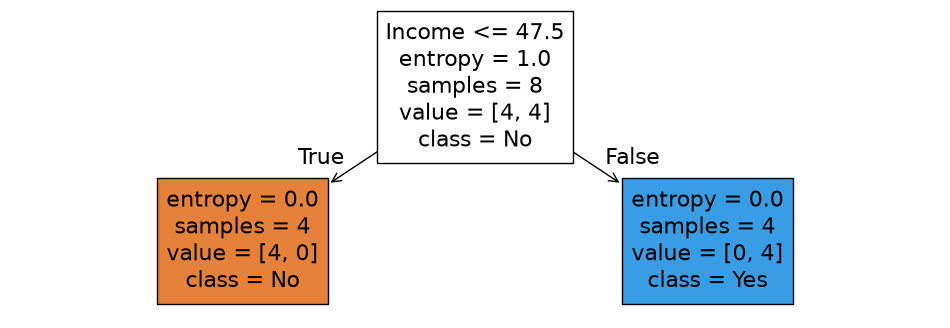

In [15]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize = (12,4))
plot_tree(
    model,
    feature_names = X.columns,
    class_names = ["No", "Yes"],
    filled = True
)

plt.show()

# Overfiting / Underfiting / bestfit 

Overfiting, Underfiting, bestfit ?

ans: 
~~~~ text
Overfitting occurs when a model is too complex and performs well on the training data but poorly on the test data. Underfitting occurs when a model is too simple and performs poorly on both the training and test data. Best fit is when a model performs well on both the training and test data.
~~~~


# Random Forest Classifier

what is randomforest?
~~~~ test
Random Forest is an ensemble learning method used for classification, regression, and other tasks that operates by constructing multiple decision trees during training and outputting the mode of the classes (classification) or mean prediction (regression) of the individual trees. It is a type of bagging technique that helps to improve the accuracy and robustness of the model by reducing overfitting.
~~~~



**what is bagging?**
~~~~ text
Bagging (Bootstrap Aggregating) is an ensemble technique used to improve the stability and accuracy of machine learning algorithms. It involves creating multiple subsets of the original dataset by sampling with replacement, training a separate model on each subset, and then combining the predictions of all models to make a final prediction. This helps to reduce overfitting and improve the generalization of the model.
~~~~

what is boosting?
~~~~ text
Boosting is an ensemble learning technique that combines multiple weak learners to create a strong learner. It works by training models sequentially, where each subsequent model focuses on correcting the errors of the previous models. The final prediction is made by combining the predictions of all the individual models, typically with a weighted sum. This approach helps to reduce both bias and variance, leading to improved performance.
~~~~

**where difference between bagging and boosting?**
~~~~ test
The main difference between bagging and boosting lies in how they build and combine models:
- In bagging, multiple models are trained independently on different subsets of the data, and their predictions are combined through averaging (for regression) or voting (for classification).
- In boosting, models are trained sequentially, with each subsequent model focusing on correcting the errors of the previous models. The final prediction is made by combining the predictions of all the individual models, typically with a weighted sum.
~~~~



**difference between random forest and decision tree in table?**
| Feature | Decision Tree | Random Forest |
|---------|---------------|----------------|
| Number of trees | 1 | Multiple |
| Tree correlation | Independent | Correlated |
| Overfitting | Prone to overfitting | Less prone to overfitting |
| Accuracy | May be less accurate | Generally more accurate |
| Interpretability | Easy to interpret | Harder to interpret |




**Randomness in random forest?** 

Randomness in Random Forest is introduced in two main ways:
1. **Bootstrap Sampling**: Each tree is trained on a different bootstrap sample of the original dataset, which means that each tree sees a slightly different subset of the data.
2. **Feature Randomness**: At each node, only a random subset of features is considered for splitting, which helps to decorrelate the trees and improve the overall performance of the ensemble.



what is difference between underfitting and overfitting in simple words?
- **Underfitting**: The model is too simple and fails to capture the patterns in the training data, leading to poor performance on both training and test data.
- **Overfitting**: The model is too complex and captures noise in the training data, leading to excellent performance on training data but poor performance on test data.   


when to use random forest and when to use decision tree?
- **Decision Tree**: Use when you need a simple, interpretable model and the dataset is not too large or complex. It is suitable for small to medium-sized datasets and when you want to understand the decision-making process.
- **Random Forest**: Use when you need higher accuracy and robustness, especially for larger and more complex datasets. It is suitable for situations where overfitting is a concern and when you want to leverage the power of ensemble learning to improve predictions.




### Parameter of randoem forest

- n_estimators = Number of tree
- Max_depth = Maximum depth of each tree
- max_depth = Number of feature consider during each split
- min_sampls_leaf = Minimum samples requred in a leaf

In [1]:
data = {
    "Age" : [22,25,30,35,40,45,50,28,32,38],
    "Salary" : [25000, 30000, 40000, 50000, 60000, 70000, 80000, 90000,
                450000, 55000],
    "Experience" : [1,2,4,7,10,15,20,3,5,8],
    "Purachesed" : [0,0,0,1,1,1,1,0,1,1]
}

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.DataFrame(data)

In [4]:
df

,Age,Salary,Experience,Purachesed
0,22,25000,1,0
1,25,30000,2,0
2,30,40000,4,0
3,35,50000,7,1
4,40,60000,10,1
5,45,70000,15,1
6,50,80000,20,1
7,28,90000,3,0
8,32,450000,5,1
9,38,55000,8,1


In [7]:
# split

Y = df[["Purachesed"]]
X = df.drop(["Purachesed"], axis = 1)

# Train Test Split

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
xtrain,xtest,ytrain,ytest = train_test_split(X, Y, test_size = 0.2, random_state = 42)

# model train

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Create a Random Forest Classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit the model
clf.fit(xtrain, ytrain)

# Make predictions
y_pred = clf.predict(xtest)

D:\SevenMentor\ML\workspace\.ml_work\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


# accuracey

In [13]:
from sklearn.metrics import accuracy_score as acc, confusion_matrix as cm


print(acc(y_pred, ytest))
print(cm(y_pred, ytest))

0.5
[[1 1]
 [0 0]]


# plot

In [18]:
# import matplotlib.pyplot as plt
# from sklearn.tree import plot_tree
# from sklearn.tree._classes import DecisionTreeClassifier
    
# plt.figure(figsize = (12,4))
# DecisionTreeClassifier(
#     clf,
#     class_names = ["No", "Yes"],
#     filled = True
# )

# plt.show()

# train medel on Loan dataset

In [4]:
import pandas as pd
loan = pd.read_csv(r"D:\SevenMentor\ML\workspace\Dhanaji_ml\dataset\loan_approval_dataset.csv")

In [5]:
dataset

NameError: name 'dataset' is not defined

In [6]:
loan.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [7]:
loan.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [8]:
loan.isna().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

In [9]:
loan.duplicated().sum()

np.int64(0)

In [10]:
# EDA




In [11]:
# FE

cat = []
cot = []

for i in loan.columns:
    if loan[i].dtype == "str":
        cat.append(i)
    else:
        cot.append(i)
        

In [12]:
cat

[' education', ' self_employed', ' loan_status']

In [13]:
cot

['loan_id',
 ' no_of_dependents',
 ' income_annum',
 ' loan_amount',
 ' loan_term',
 ' cibil_score',
 ' residential_assets_value',
 ' commercial_assets_value',
 ' luxury_assets_value',
 ' bank_asset_value']

In [24]:
# perfom lable encoding

for i in cat:
    print(loan[i].value_counts(), "\n")


from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

 education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64 

 self_employed
Yes    2150
No     2119
Name: count, dtype: int64 

 loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64 



In [26]:
for i in cat:
    loan[i] = le.fit_transform(loan[i])

In [27]:
loan

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,0,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,0
1,2,0,1,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,1
2,3,3,0,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,1
3,4,3,0,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,1
4,5,5,1,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,0,1,1000000,2300000,12,317,2800000,500000,3300000,800000,1
4265,4266,0,1,1,3300000,11300000,20,559,4200000,2900000,11000000,1900000,0
4266,4267,2,1,0,6500000,23900000,18,457,1200000,12400000,18100000,7300000,1
4267,4268,1,1,0,4100000,12800000,8,780,8200000,700000,14100000,5800000,0


## split data

In [38]:
from sklearn.model_selection import train_test_split


Y = loan[[" loan_status"]]
X = loan.drop([" loan_status"], axis = 1)

In [43]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

In [48]:
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(3415, 12) (854, 12) (3415, 1) (854, 1)


## train model

In [65]:
# from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier

# Create a Random Forest Classifier
# clf = RandomForestClassifier(n_estimators=100, random_state=42)\
model = RandomForestClassifier(n_estimators=100, random_state=42, criterion="entropy")




In [66]:
model.fit(x_train, y_train)

D:\SevenMentor\ML\workspace\.ml_work\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap boot

In [67]:
y_pred_test = model.predict(x_test)

In [68]:
y_pred_train = model.predict(x_train)

In [69]:
from sklearn.metrics import accuracy_score
# from sklearn.metrics import accuracy_score as acc, confusion_matrix as cm

print("Accuracy on test data: ",accuracy_score(y_pred_test, y_test))
print("Accuracy on train data: ",accuracy_score(y_pred_train, y_train))

Accuracy on test data:  0.9789227166276346
Accuracy on train data:  1.0
